In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# Recetas para investigar

Tres tareas que se repiten en los trabajos con la GEIH, con los ocupados de 2025: una ecuación de salarios
de Mincer ponderada, la descomposición de Oaxaca-Blinder de la brecha entre hombres y mujeres y una tabla
lista para LaTeX. Solo usan numpy y pandas.

```{admonition} Solo estimaciones puntuales
:class: warning

Las estimaciones usan el factor de expansión como peso, así que representan a la población. Los errores
estándar de mínimos cuadrados ponderados, en cambio, no tienen en cuenta el diseño de la muestra
(conglomerados y estratos) y suelen quedar demasiado pequeños: por eso aquí no se muestran.
```

In [2]:
import numpy as np

import dane_data as dd

df = dd.geih.load(2025, variables=["fex", "ocupado", "sexo", "edad", "nivel_educativo", "horas_semana",
                                   "ingreso_laboral"])
ocupados = df[(df.ocupado == 1) & (df.ingreso_laboral > 0) & (df.horas_semana > 0)].dropna(
    subset=["nivel_educativo"])
len(ocupados)

347190

## Una ecuación de Mincer ponderada

El logaritmo del ingreso laboral mensual se explica con el nivel educativo (frente a «Ninguno»), la edad y
su cuadrado (en lugar de la experiencia), el logaritmo de las horas trabajadas a la semana y el sexo.
Mínimos cuadrados ponderados es mínimos cuadrados ordinarios después de multiplicar cada fila por la raíz
de su peso:

In [3]:
def disenio(d, mujer=True):
    """Matriz de variables explicativas: constante, nivel educativo, edad, edad²/100, horas y sexo."""
    X = pd.get_dummies(d["nivel_educativo"], drop_first=True, dtype=float)   # «Ninguno» es la base
    X.insert(0, "constante", 1.0)
    X["edad"] = d["edad"]
    X["edad2"] = d["edad"] ** 2 / 100
    X["ln_horas"] = np.log(d["horas_semana"])
    if mujer:
        X["mujer"] = (d["sexo"] == "Mujer").astype(float)
    return X


def mco_ponderado(y, X, w):
    """Coeficientes de mínimos cuadrados ponderados por w."""
    raiz = np.sqrt(w.to_numpy())
    beta, *_ = np.linalg.lstsq(X.to_numpy() * raiz[:, None], y.to_numpy() * raiz, rcond=None)
    return pd.Series(beta, index=X.columns)


ln_ingreso = np.log(ocupados["ingreso_laboral"])
mincer = mco_ponderado(ln_ingreso, disenio(ocupados), ocupados["fex"])
mincer.round(3).to_frame("coeficiente")

,coeficiente
constante,9.098
Primaria,0.305
Secundaria,0.447
Media,0.669
Superior,1.386
edad,0.045
edad2,-0.046
ln_horas,0.880
mujer,-0.211


Un coeficiente $b$ de una variable 0/1 es una diferencia de $100\,(e^{b} - 1)$ % en el ingreso, con lo
demás igual:

In [4]:
(100 * (np.exp(mincer[["Primaria", "Secundaria", "Media", "Superior", "mujer"]]) - 1)).round(1).to_frame("%")

,%
Primaria,35.7
Secundaria,56.4
Media,95.1
Superior,299.9
mujer,-19.0


Con lo demás igual, quien tiene educación superior gana unas cuatro veces lo que gana quien no tiene
educación (300 % más), y una mujer gana 19 % menos que un hombre de la misma educación, edad y horas. El
coeficiente de las horas, 0,88, dice que el ingreso mensual crece casi en proporción a las horas.

Con [statsmodels](https://www.statsmodels.org) da los mismos coeficientes:
`smf.wls("np.log(ingreso_laboral) ~ C(nivel_educativo) + edad + I(edad**2 / 100) + np.log(horas_semana) + C(sexo)", ocupados, weights=ocupados["fex"]).fit()`.
Si necesita errores estándar, agruparlos por vivienda (`.fit(cov_type="cluster", cov_kwds={"groups": ...})` con
`DIRECTORIO`, que se pide en `variables`) tiene en cuenta que las personas de un mismo hogar se parecen, pero
tampoco son los errores del diseño muestral.

## Los retornos de la educación, por sexo

La misma ecuación, estimada aparte para hombres y para mujeres (sin la variable `mujer`):

In [5]:
hombres = ocupados[ocupados.sexo == "Hombre"]
mujeres = ocupados[ocupados.sexo == "Mujer"]
b_hombres = mco_ponderado(np.log(hombres["ingreso_laboral"]), disenio(hombres, mujer=False), hombres["fex"])
b_mujeres = mco_ponderado(np.log(mujeres["ingreso_laboral"]), disenio(mujeres, mujer=False), mujeres["fex"])

niveles = ["Primaria", "Secundaria", "Media", "Superior"]
retornos = pd.DataFrame({"Hombres": b_hombres[niveles], "Mujeres": b_mujeres[niveles]})
retornos = 100 * (np.exp(retornos) - 1)
retornos.round(1)

,Hombres,Mujeres
Primaria,33.3,43.9
Secundaria,53.8,68.4
Media,87.6,119.1
Superior,267.4,358.9


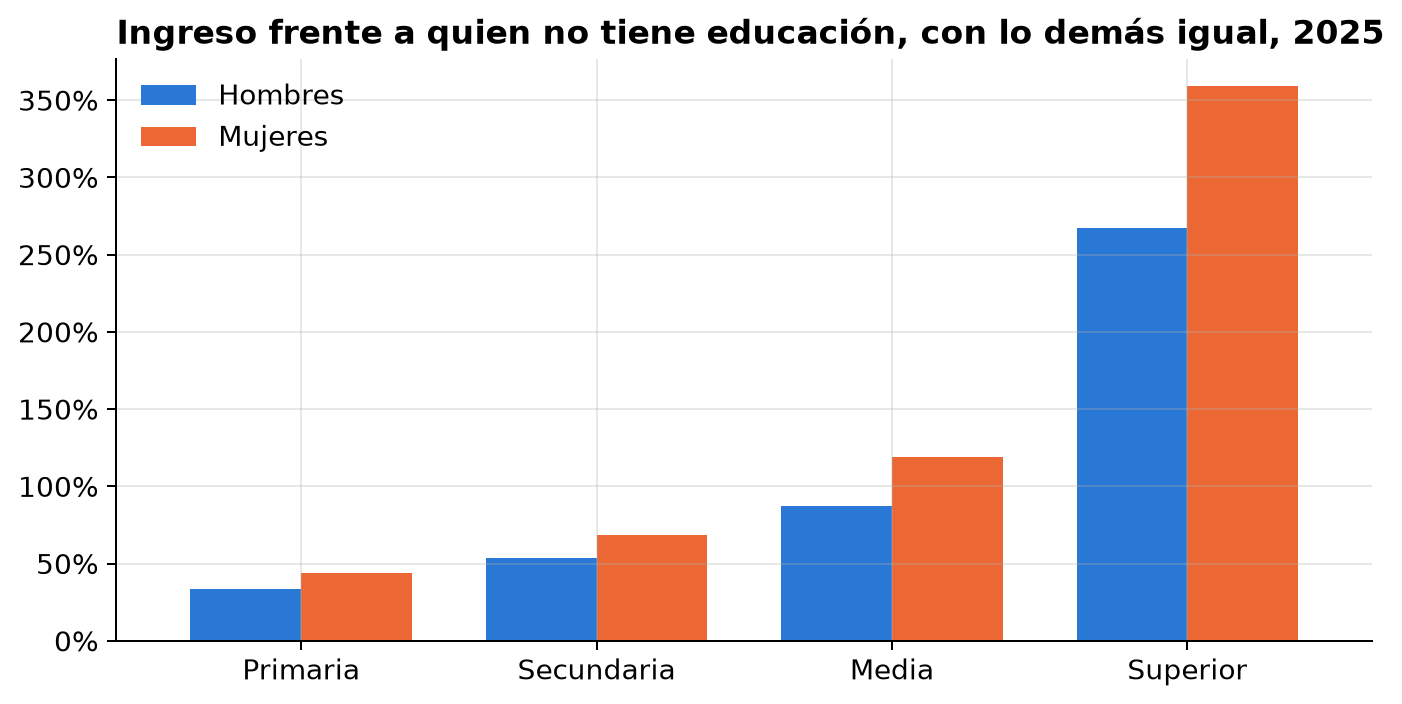

In [6]:
ax = retornos.plot.bar(rot=0, width=0.75)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("")
ax.set_title("Ingreso frente a quien no tiene educación, con lo demás igual, 2025")
ax.legend(title="");

En proporción, la educación se les paga más a las mujeres: con educación superior, ellas ganan 359 % más
que las mujeres sin educación, y ellos 267 % más que los hombres sin educación. Cada barra compara dentro
del mismo sexo; la constante de las mujeres es más baja.

## La descomposición de Oaxaca-Blinder

La brecha de ingresos entre hombres ($H$) y mujeres ($M$), en logaritmos, se parte en dos: lo que se
explica porque tienen características distintas (educación, edad, horas) y lo que no, porque las mismas
características se pagan distinto. Con los coeficientes de los hombres como referencia:

$$
\bar y_H - \bar y_M = \underbrace{(\bar X_H - \bar X_M)\,\beta_H}_{\text{explicada}}
+ \underbrace{\bar X_M\,(\beta_H - \beta_M)}_{\text{no explicada}}
$$

Las medias van ponderadas con el factor de expansión, así que la suma da exactamente la brecha:

In [7]:
def media_ponderada(X, w):
    return X.mul(w, axis=0).sum() / w.sum()


x_hombres = media_ponderada(disenio(hombres, mujer=False), hombres["fex"])
x_mujeres = media_ponderada(disenio(mujeres, mujer=False), mujeres["fex"])
brecha = (np.average(np.log(hombres["ingreso_laboral"]), weights=hombres["fex"])
          - np.average(np.log(mujeres["ingreso_laboral"]), weights=mujeres["fex"]))
explicada = (x_hombres - x_mujeres) * b_hombres
no_explicada = x_mujeres * (b_hombres - b_mujeres)

oaxaca = pd.Series({"brecha": brecha, "explicada": explicada.sum(), "no explicada": no_explicada.sum()})
(100 * oaxaca).round(1).to_frame("puntos logarítmicos")

,puntos logarítmicos
brecha,20.0
explicada,-2.8
no explicada,22.8


Los hombres ocupados ganan en promedio 20 puntos logarítmicos más que las mujeres, unos 22 %
($100\,(e^{0{,}200} - 1)$). La parte explicada es negativa: por su educación, su edad y sus horas, las
mujeres deberían ganar un poco más que los hombres, así que toda la brecha, y algo más (22,8 puntos),
queda sin explicar. Por grupo de variables:

In [8]:
grupos = {"Educación": niveles, "Edad": ["edad", "edad2"], "Horas": ["ln_horas"]}
(100 * pd.Series({g: explicada[v].sum() for g, v in grupos.items()})).round(1).to_frame("parte explicada")

,parte explicada
Educación,-14.5
Edad,-0.8
Horas,12.5


Las dos fuerzas casi se compensan: los hombres trabajan más horas, lo que explica 12,5 puntos de la
brecha, pero las mujeres ocupadas tienen más educación, lo que la reduce en 14,5. La edad casi no cuenta.
La parte de cada grupo de variables no depende de la categoría que se deje como base; la de cada nivel
educativo por separado, sí. La parte no explicada no mide directamente la discriminación: incluye todo lo
que la ecuación no tiene en cuenta, como la ocupación, el sector o la experiencia laboral real.

## Una tabla para LaTeX

`DataFrame.to_latex` escribe la tabla con el formato de `booktabs` (`\toprule`, `\midrule`); el
documento necesita `\usepackage{booktabs}`:

In [9]:
tabla = pd.DataFrame({"Todos": mincer, "Hombres": b_hombres, "Mujeres": b_mujeres}).reindex(mincer.index)
print(tabla.to_latex(float_format="%.3f", na_rep="", caption="Ecuación de Mincer ponderada, GEIH 2025",
                     label="tab:mincer"))

\begin{table}
\caption{Ecuación de Mincer ponderada, GEIH 2025}
\label{tab:mincer}
\begin{tabular}{lrrr}
\toprule
 & Todos & Hombres & Mujeres \\
\midrule
constante & 9.098 & 9.675 & 8.456 \\
Primaria & 0.305 & 0.287 & 0.364 \\
Secundaria & 0.447 & 0.431 & 0.521 \\
Media & 0.669 & 0.629 & 0.784 \\
Superior & 1.386 & 1.301 & 1.524 \\
edad & 0.045 & 0.047 & 0.046 \\
edad2 & -0.046 & -0.048 & -0.049 \\
ln_horas & 0.880 & 0.724 & 0.963 \\
mujer & -0.211 &  &  \\
\bottomrule
\end{tabular}
\end{table}



Para guardarla, `tabla.to_latex("mincer.tex", ...)`. Las tablas de {dd}`tabla()` y de las funciones
`serie_*` también son `DataFrame`, así que se exportan igual.

```{seealso}
* {doc}`../guia/ponderacion`: por qué el peso es el factor de expansión y cómo se promedian los meses.
* {doc}`brecha_genero`: la brecha de ingresos por nivel educativo, sin regresiones.
```